## **E-R Diagrams**


### **1. What is an E-R Diagrma?**

An **E-R Diagram** _(Entity-Relationship Diagram)_ is a graphical representations of database's:
- entities
- attributes
- keys
- relationship
- cardinality
- participation contstraints

Think of it as the **blueprint of database**.

The E-R Diagram is where we can look at the proposed database and visually understand:
> "What things exist, what information do we store about them, and how are they connected?"

#### **Why do we need an E-R Diagram?**

The diagrma helps us to answer question quickly:
- What entities exist?
- What attributes belong to each?
- What is the primary key?
- Which entities are related?
- Is the relationship 1:1, 1:N, or M:N?
- Is the participation mandotary?
- Does the relationship has its own attributes?

### **2. Basic E-R Diagra Symbols**

In the traditional **Chen notation**, the major symbols are:
| **Symbol** | **Represents** |
|------------|----------------|
| Rectangle | Entity set |
| Diamond | Relationship set |
| Oval | Attribute |
| Underlined attribute | Key attribute |
| Double Oval | Multivalued attribute |
| Dashed oval | Derived attribute |
| Double rectangle | Weak entity |
| Double diamond | Identifying relationship |
| Line | Connection |
| Double line | Total participation |

### **The image might help more**

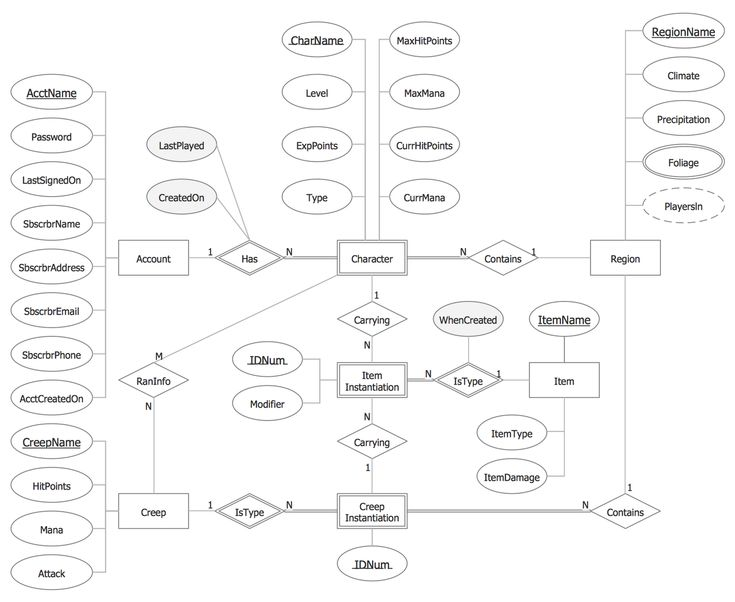

### **How to Read an E-R Diagram**

**Step 1 - What are the rectangles?**

Those are the entities.

**Step 2 - What are the ovals?**

Those are the attributes.

**Step 3 - Which attributes are keys?**

Look for underlined one.

**Step 4 - What are diamonds?**

Those relationship.

**Step 5 - What attributes belong to relationships?**

Look at the ovals connected to diamonds.

**Step 6 - What is the cardinality?**

1:1? or 1:N? or M:N?

**Step 7 - Is participation mandotary?**

Look for total/partial participation.

**Step 8 - Are there special attributes?**

Composite?

Multivalued?

Derived?

This gives us a complete interpretation.

### **Let's test the skill**

A university has:
- Students
- Departments
- Courses

Each student belongs to exactly one department.

Each department can have many students.

A department offers any courses.

A course belongs to exactly one department.

A student can enroll in many courses.

A course can have many students.

For every enrollement, the university records:

- Enrollement_Date
- Grade

Student has:
- Student_ID
- Name
- DOB

Course has:
- Course_ID
- Course_Name

Department has:
- Department_ID
- Department_Name

**OUR TASK**

Find:
1. All entities
2. Attributes of each entity
3. All relationships 
4. Cardinality of each relationship
5. Which attributes belong to the relationship?
6. Which attributes are keys?
7. Finally, draw the E-R diagram.

**Answer**

Entities (STUDENT, DEPARTMENT, COURSES)

Attributes:

- STUDENT (Student_ID, Name, DOB)
- COURSES (Course_ID, Course_Name)
- DEPARTMENTS (Dept_ID, Dept_Name)

Relationship:

- STUDENT N ------- Have -------- 1 DEPARTMENT
- DEPARTMENT 1 -------- Offers -------- N COURSES
- STUDENT M --------- Enrolls --------- N COURSES

Relationship attribute:

- ENROLLS (Enrollment_Data, Grade)

Key attributes:

- STUDENT -> Student_ID
- COURSES -> Course_ID
- DEPARTMENT -> Dept_ID

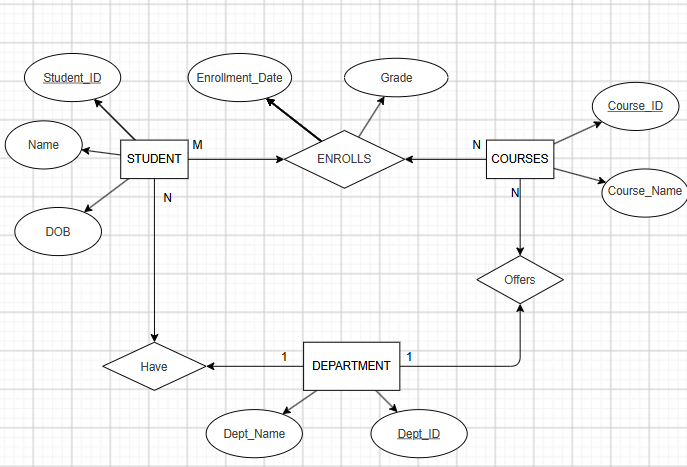


### **Reduction of E-R Diagrams to Relational Schemas**

This is one of the most important topics in database design because it connects our **conceptual design** to the actual tables we create using SQL.

**The big picture**
```text 
Real-world requirements (What does the university need to store?)
                            |
E-R Diagrams (Entities, attributes, relationships and constraints)
                            |
Relational schema (Tables, columns, primary keys and foreign keys)
                            |
SQL Implementation (CREATE TABLE, PRIMARY KEY, FOREIGN KEY, etc.)
```

**Simple english:** An E-R diagram is a conceptual representation. A relational schema specifies the tables and their structures.

#### **Rule 1 - Convert a strong entity into a table**

Every regular (strong) entity set normally becomes its own relation.

Suppose our E-R diagrma contains:
- STUDENT
- DEPARTMENT
- COURSE

Each becomes a separate table.

**NOTE**: The attribute belongs to each entity become columns of its corresponding table.

#### **Rule 2 - Convert a one-to-one (1:1) relationship**

Suppose we have this requriement:
> Each person has at most one passport, and each passport belongs to at most one person.

Enities:
- PERSON
- PASSPORT

Relationship:

-HAS -> 1:1

There are several ways to map a 1:1 relationship. A common approach is to put one entity's primary key as a foreign key in the other table.

For Example:
```SQL
CREATE TABLE PERSON(
    Person_ID PRIMARY KEY,
    Name VARCHAR(50),
)

CREATE TABLE PASSPORT(
    Passport_ID PRIMARY KEY,
    Person_ID UNIQUE,
    FOREIGN KEY (Person_ID) REFERENCES PERSON(Person_ID)
)
```
Why `UNIQUE`?

Because a person must not be linked to multiple passport rows under this simplified one-passport-per-person model.

Why a foreign key?

Because a passport must refer to an existing person.

If every passport must belong to a person, `Person_ID` should also be `NOT_NULL`.


#### **Rule 3 - Convert a one-to-many (1:N) relationship**

The requirement is:
> One department can have many students, but every student belongs to exactly one department.

The relationship is:

**DEPARTMENT 1 : N STUDENTS**

Which table should receive the foreign key?

Answer: **The table on the many side.**

So `Dept_ID` goes into `STUDENT`.

```text
DEPARTMENT(Dept_ID, Dept_Name)

STUDENT(Student_ID, Name, DOB, Dept_ID)
PK: Student_ID, FK: Dept_ID
```
The foreign key connects each student to a department.

For our stated rule, every student must belong to exactly one department, so `Dept_ID` must be `NOT NULL`

```SQL
CREATE TABLE DEPARTMENT(
    Dept_ID INT PRIMARY KEY,
    Dept_Name VARCHAR(100)
);

CREATE TABLE STUDENT(
    Student_ID INT PRIMARY KEY,
    Name VARCHAR(50) NOT NULL,
    DOB DATE,
    Dept_ID INT NOT NULL,

    FOREIGN KEY (Dept_ID) REFERENCES DEPARTMENT(Dept_ID)
);
```

**Why the many side?**

Imagine 500 students belonging to the Commerce department. Each student row can store the same `Dept_ID`, while the department's details are stored just onece in `DEPARMENT`.

We do not need to put hundreds of `Student_ID` values into the department row.

#### **Apply that rule to DEPARTMENT - OFFERS - COURSE**

The requirement:
> A department offers many courses, and everey course belongs to exactly one department.

Therefore:

**DEPARTMENT 1 : N COURSES**

The foreign key goes into `COURSE`.

```text
DEPARTMENT (Dept_ID, Dept_Name)

COURSE (Course_ID, Course_Name, Dept_ID)
PK: Course_ID, FK: Dept_ID
```

SQL implementation:
```SQL
CREATE TABLE COURSE(
    Course_ID INT PRIMARY KEY,
    Course_Name VARCHAR(100) NOT NULL,
    Dept_ID INT NOT NULL,

    FOREIGN KEY (Dept_ID) REFERENCES DEPARTMENT(Dept_ID)
)
```
Now each course row identifies its department.

#### **Rule 4 - Convert a many-to-many (M:N) relationship**

Now for the most important relationship in our diagram:

**STUDENT M : N COURSE**

A student can enroll in many courses, and each course can have many students.

Can we simply add `Course_ID` to STUDENT?

Not if students can take multiple course while we want to represent each enrollment separately. A single `Course_ID` column would allow only one course value per student row in a conventional normalized design.

Can we add `Student_ID` to COURSE instead?

That would similarly fail to represent many students per course in one ordinary column.

Sow we create a **new table for the relationship**.

Its name can be ENROLLMENT.

```text
ENROLLMENT(
    Student_ID,
    Course_ID,
    Enrllment_date,
    Grade
)
```

The keys are:
- `Student_ID` -> foreign key referencing STUDENT
- `Course_ID` -> foreign key referencing COURSE
- `(Student_ID, Course_ID)` combined Composite Primary key.

```SQL
CREATE TABLE ENROLLMENT(
    Student_ID INT,
    Course_ID INT,
    Enrollment_Date DATE NOT NULL,
    GRADE VARCHAR(2),

    PRIMARY KEY (Student_ID, Course_ID),
    FOREIGN KEY (Student_ID) REFERENCES STUDENT(Student_ID),
    FOREIGN KEY (Course_ID) REFERENCES COURSE(Course_ID)
);
```

### **Summary of the conversion rules**

| **E-R construct** | **Relational mapping** |
| ----------------- | ---------------------- |
| Strong entity  | Create table |
| 1:1 Relationship | Put a foreign key on an appropriate side; enforce uniqueness |
| 1:N Relationship | Put a foreign key on the N side |
| M:N Relationship | Create a separate relationship table |
| Relationship attributes | Store them with the relationship, often in its table |
| Multivalued attribute | Create a separate table |
| Weak entity | Create a table including its owner's key |